# Understanding Multi-Armed Bandits: Dynamic Pricing

A shop sells one product online and can show each visitor any of a handful of prices. A high price earns more per sale but fewer people buy; a low price sells more but earns less on each sale. The shop does not know how demand responds to price, so it has to learn that while it sells. Every visitor shown a bad price is revenue lost for good.

That is a **multi-armed bandit**: reinforcement learning with a single state. Each price is an *arm*, each visitor is one *pull*, and the reward is the revenue from that visitor. There is no next state to plan for, which leaves the one problem every RL algorithm has to solve in its purest form: **explore** prices that might be better, or **exploit** the one that looks best so far.

This notebook answers [issue #1](https://github.com/FareedKhan-dev/all-rl-algorithms/issues/1), which asked how RL applies to dynamic pricing in e-commerce, and follows the Thompson Sampling approach proposed there by @MenokoOG.

## The goal: low regret

Let $\mu_k$ be the expected revenue per visitor at price $k$, and $\mu^* = \max_k \mu_k$ the best of them. If the shop shows price $A_t$ to visitor $t$, its **regret** after $T$ visitors is the revenue it gave up against always showing the best price:

$$
\text{Regret}(T) = T\,\mu^* - \sum_{t=1}^{T} \mu_{A_t}
$$

A strategy that never stops exploring has regret that grows linearly with $T$. A good bandit algorithm explores less as it learns, so in the long run its regret grows only like $\log T$. How fast it gets there depends on the algorithm and the problem. We compare three classic strategies on exactly this measure.

| Strategy | Chooses | Explores by |
|---|---|---|
| **ε-greedy** | the best price so far | a random price with probability ε |
| **UCB1** (Auer et al., 2002) | the price with the highest *optimistic* estimate | adding a bonus that shrinks as a price is tried more |
| **Thompson Sampling** (Thompson, 1933) | the best price under one *sampled* guess of demand | sampling that guess from what it has seen so far |

## Setting up the environment

Each visitor buys with a probability that falls as the price rises. We model that with a logistic demand curve, a common shape in pricing: almost everyone buys at a very low price, almost nobody at a very high one, and the steepest drop sits around a reference price $p_0$:

$$
P(\text{buy} \mid p) = \frac{1}{1 + e^{(p - p_0)/s}}
$$

The expected revenue per visitor at price $p$ is $p \cdot P(\text{buy} \mid p)$. Because we simulate the shop, we know this curve exactly, which is what lets us measure regret. The agents never see it: they only see whether each visitor bought.

In [1]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

PRICES = np.array([10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0])  # the arms
P0, SCALE = 28.0, 5.0  # reference price and steepness of the demand curve


class PricingEnv:
    # One product, one price per visitor; the visitor buys with the logistic probability above.

    def __init__(self, prices: np.ndarray, p0: float, scale: float, seed: int) -> None:
        self.prices = prices
        self.buy_prob = 1.0 / (1.0 + np.exp((prices - p0) / scale))
        self.expected_revenue = prices * self.buy_prob
        self.best = int(np.argmax(self.expected_revenue))
        self.rng = np.random.default_rng(seed)

    def visit(self, arm: int) -> tuple[bool, float]:
        # Show price `arm` to one visitor; return (bought, revenue).
        bought = bool(self.rng.random() < self.buy_prob[arm])
        return bought, float(self.prices[arm]) if bought else 0.0


env = PricingEnv(PRICES, P0, SCALE, seed=0)
for p, q, r in zip(env.prices, env.buy_prob, env.expected_revenue):
    print(f"price {p:5.1f}  buys {q:6.1%}  expected revenue per visitor {r:6.2f}")
print(f"\nBest price: {env.prices[env.best]:.0f}, earning {env.expected_revenue[env.best]:.2f} per visitor")

price  10.0  buys  97.3%  expected revenue per visitor   9.73
price  15.0  buys  93.1%  expected revenue per visitor  13.96
price  20.0  buys  83.2%  expected revenue per visitor  16.64
price  25.0  buys  64.6%  expected revenue per visitor  16.14
price  30.0  buys  40.1%  expected revenue per visitor  12.04
price  35.0  buys  19.8%  expected revenue per visitor   6.92
price  40.0  buys   8.3%  expected revenue per visitor   3.33
price  45.0  buys   3.2%  expected revenue per visitor   1.45

Best price: 20, earning 16.64 per visitor


The best price is neither the cheapest nor the most expensive: below it the shop leaves money on the table with every sale, above it too many visitors walk away. Notice too how close the neighbouring prices are. Telling them apart takes many visitors, which is what makes the exploration problem real.

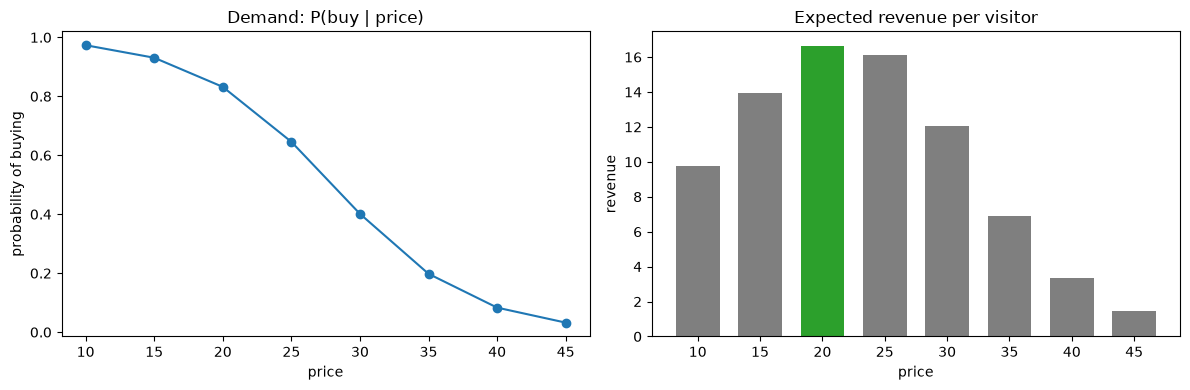

In [2]:
# Plot the demand curve and the revenue curve the agents have to discover
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(env.prices, env.buy_prob, "o-")
ax[0].set(title="Demand: P(buy | price)", xlabel="price", ylabel="probability of buying")
ax[1].bar(env.prices, env.expected_revenue, width=3.5, color=["tab:green" if i == env.best else "tab:gray" for i in range(len(env.prices))])
ax[1].set(title="Expected revenue per visitor", xlabel="price", ylabel="revenue")
plt.tight_layout()
plt.show()

## Implementing the three strategies

All three keep, for every price $k$, how often it was shown $n_k$ and the revenue it earned. They differ only in how they pick the next price.

**ε-greedy** shows the best price so far, except with probability $\varepsilon$, when it shows a random one. Simple, but it keeps exploring at the same rate forever, so its regret grows linearly.

**UCB1** shows the price with the highest *upper confidence bound* on its revenue:

$$
A_t = \arg\max_k \; \hat\mu_k + c\,\sqrt{\frac{2 \ln t}{n_k}}
$$

The bonus is large for prices tried rarely and shrinks as $n_k$ grows: optimism in the face of uncertainty. UCB1 assumes rewards in $[0, 1]$; revenue lies in $[0, p_{\max}]$, so the bonus is scaled by $c = p_{\max}$.

**Thompson Sampling** keeps a *belief* about each price's purchase probability, a Beta distribution: starting from $\text{Beta}(1, 1)$ (uniform), each sale adds one to $\alpha_k$ and each visitor who leaves adds one to $\beta_k$. For each visitor it samples one guess $\theta_k \sim \text{Beta}(\alpha_k, \beta_k)$ for every price and shows the price that would earn the most if that guess were true:

$$
A_t = \arg\max_k \; p_k \, \theta_k
$$

A price it is unsure about sometimes gets a high sample and is tried; a price it is confident is bad almost never does.

In [3]:
class EpsilonGreedy:
    def __init__(self, n_arms: int, epsilon: float, rng: np.random.Generator) -> None:
        self.epsilon, self.rng = epsilon, rng
        self.n = np.zeros(n_arms)
        self.revenue = np.zeros(n_arms)

    def select(self, t: int) -> int:
        if t < len(self.n):                      # show every price once first
            return t
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(len(self.n)))
        return int(np.argmax(self.revenue / self.n))

    def update(self, arm: int, bought: bool, revenue: float) -> None:
        self.n[arm] += 1
        self.revenue[arm] += revenue


class UCB1:
    def __init__(self, n_arms: int, reward_scale: float) -> None:
        self.c = reward_scale                    # revenue lies in [0, max price]
        self.n = np.zeros(n_arms)
        self.revenue = np.zeros(n_arms)

    def select(self, t: int) -> int:
        if t < len(self.n):
            return t
        bonus = self.c * np.sqrt(2.0 * np.log(t + 1) / self.n)
        return int(np.argmax(self.revenue / self.n + bonus))

    def update(self, arm: int, bought: bool, revenue: float) -> None:
        self.n[arm] += 1
        self.revenue[arm] += revenue


class ThompsonSampling:
    def __init__(self, prices: np.ndarray, rng: np.random.Generator) -> None:
        self.prices, self.rng = prices, rng
        self.alpha = np.ones(len(prices))        # Beta(1, 1): no idea yet
        self.beta = np.ones(len(prices))

    def select(self, t: int) -> int:
        theta = self.rng.beta(self.alpha, self.beta)   # one guess of every purchase probability
        return int(np.argmax(self.prices * theta))

    def update(self, arm: int, bought: bool, revenue: float) -> None:
        if bought:
            self.alpha[arm] += 1
        else:
            self.beta[arm] += 1

## Running the experiment

Each strategy serves $T = 5{,}000$ visitors, and we repeat that over 20 independent runs (different random visitors and different exploration luck) to average out noise. We record the expected revenue of every price it shows, which gives the regret exactly, without the noise of individual sales.

In [4]:
def run(make_agent, seed: int, horizon: int) -> np.ndarray:
    # Return the price index the agent showed to each visitor.
    env = PricingEnv(PRICES, P0, SCALE, seed=seed)
    agent = make_agent(np.random.default_rng(seed + 10_000))
    arms = np.empty(horizon, dtype=int)
    for t in range(horizon):
        arm = agent.select(t)
        bought, revenue = env.visit(arm)
        agent.update(arm, bought, revenue)
        arms[t] = arm
    return arms


HORIZON, N_RUNS = 5_000, 20
STRATEGIES = {
    "ε-greedy (ε = 0.1)": lambda rng: EpsilonGreedy(len(PRICES), 0.1, rng),
    "UCB1": lambda rng: UCB1(len(PRICES), PRICES.max()),
    "Thompson Sampling": lambda rng: ThompsonSampling(PRICES, rng),
}

mu = env.expected_revenue
results = {}
for name, make in STRATEGIES.items():
    arms = np.stack([run(make, seed, HORIZON) for seed in range(N_RUNS)])
    regret = np.cumsum(mu.max() - mu[arms], axis=1)
    results[name] = {"arms": arms, "regret": regret}
    best_share = (arms[:, -1000:] == env.best).mean()
    print(f"{name:20s} regret after {HORIZON} visitors: {regret[:, -1].mean():7.1f} "
          f"(± {regret[:, -1].std():5.1f}) | best price in the last 1000 visits: {best_share:5.1%}")

ε-greedy (ε = 0.1)   regret after 5000 visitors:  3815.3 (± 826.3) | best price in the last 1000 visits: 91.1%


UCB1                 regret after 5000 visitors: 10934.7 (± 414.2) | best price in the last 1000 visits: 41.4%


Thompson Sampling    regret after 5000 visitors:  1758.7 (± 518.2) | best price in the last 1000 visits: 86.1%


The total revenue given up is the regret printed above; dividing it by the number of visitors gives what each strategy loses per visitor on average compared with someone who knew the demand curve from the start.

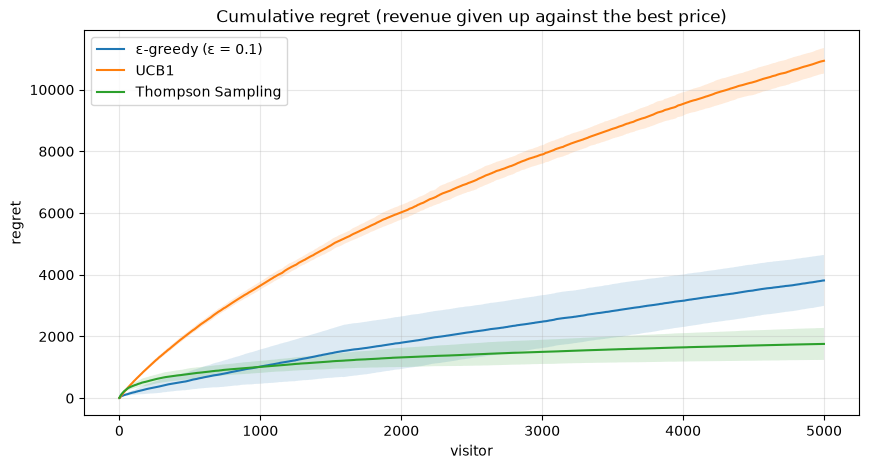

In [5]:
# Cumulative regret over time: flatter is better
plt.figure(figsize=(10, 5))
for name, res in results.items():
    mean, std = res["regret"].mean(0), res["regret"].std(0)
    plt.plot(mean, label=name)
    plt.fill_between(np.arange(HORIZON), mean - std, mean + std, alpha=0.15)
plt.title("Cumulative regret (revenue given up against the best price)")
plt.xlabel("visitor")
plt.ylabel("regret")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Reading the curves.** ε-greedy's regret grows almost in a straight line: even after it has found the best price, it keeps showing a random one to one visitor in ten, forever. Thompson Sampling pays more at the start, while it tests every price, then flattens and ends lowest by far (1,759 on average, against 3,815 for ε-greedy). It explores in proportion to how likely each price is to be the best, so it spends very few visitors on prices that are clearly worse.

UCB1 ends worst (10,935), even though its regret has the strongest guarantee on paper: it grows like $\log T$. That guarantee holds for any rewards in $[0, c]$, so the bonus is sized for the worst case, revenue anywhere between 0 and 45, while the two best prices differ by only 0.5 per visitor (16.64 at 20, 16.14 at 25). A bonus that large keeps sending visitors to the neighbours of the best price for a long time: in the last 1,000 visitors UCB1 still shows the best price to only 41% of them. Its curve does bend, but at this scale the bonus dwarfs the differences it has to resolve. Thompson Sampling's uncertainty shrinks with the data actually seen, which is why it often does better than UCB1 in practice.

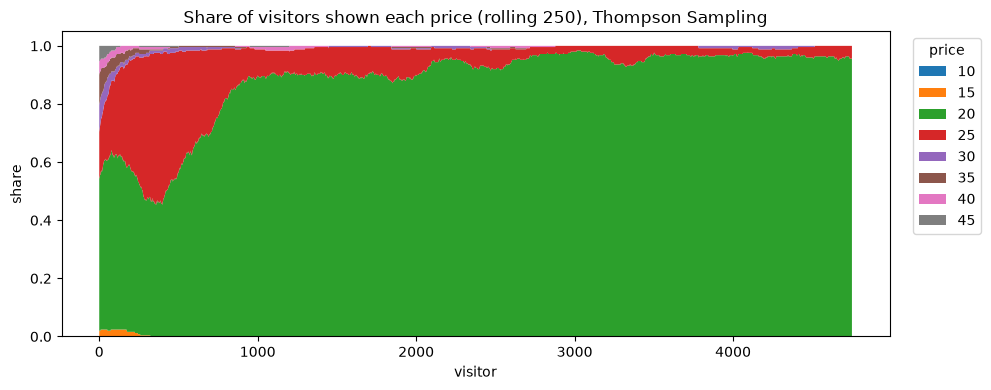

In [6]:
# Which prices did Thompson Sampling show over time? (one run)
arms = results["Thompson Sampling"]["arms"][0]
window = 250
share = np.stack([np.convolve(arms == k, np.ones(window) / window, mode="valid") for k in range(len(PRICES))])
plt.figure(figsize=(10, 4))
plt.stackplot(np.arange(share.shape[1]), share, labels=[f"{p:.0f}" for p in PRICES])
plt.title(f"Share of visitors shown each price (rolling {window}), Thompson Sampling")
plt.xlabel("visitor")
plt.ylabel("share")
plt.legend(title="price", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Early on, Thompson Sampling spreads visitors across many prices. Within a few hundred visitors it has dropped all but the best price, 20, and its closest neighbour, 25, whose expected revenues are only 3% apart. It then shifts toward 20, showing it to about 90% of visitors by visitor 1,000 and about 95% later, and it keeps testing 25 on the rest, because a few thousand sales are still not enough to rule it out completely.

## What a real pricing system adds

This simulation makes the three assumptions that make a problem a plain bandit, and each has a standard extension:

1. **Demand does not change.** Real demand shifts with seasons, campaigns and competitors. Discount old observations, or keep statistics over a sliding window, so the agent can notice the change.
2. **All visitors are alike.** Real visitors differ (device, region, returning or new). A *contextual bandit*, such as LinUCB or Thompson Sampling with a linear model, conditions the price on those features.
3. **Today's price does not affect tomorrow.** With limited stock, or prices that shape customers' expectations, today's decision changes the future state, and the problem becomes a full MDP. That is where the Q-learning, DQN and actor-critic notebooks in this repository take over.

In production, prices are also bounded by business rules (minimum margins, consistency between customers), and a new strategy is usually evaluated offline on logged data before it shows a single live price.